In [ ]:
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold

train = pd.read_csv("../data/raw/train.csv")

feature_cols = [
    "CreditScore", "Geography", "Gender", "Age", "Tenure",
    "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary",
]
cat_features = ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]
y = train["Exited"].copy()

def prepare(df, feature_cols, cat_features):
    X = df[feature_cols].copy()
    for col in cat_features:
        if pd.api.types.is_float_dtype(X[col]):
            X[col] = X[col].astype(int)
    return X

X_raw = prepare(train, feature_cols, cat_features)

## Финальная модель

Тот же CatBoost, что вошёл в блендинг туториала 6 (`depth=6, learning_rate=0.05,
l2_leaf_reg=3`), переобученный на 100% train с числом итераций, усреднённым по
5 фолдам.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_iterations = []
for train_idx, val_idx in skf.split(X_raw, y):
    m = CatBoostClassifier(
        iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=3,
        eval_metric="AUC", random_seed=42, verbose=False,
    )
    m.fit(
        X_raw.iloc[train_idx], y.iloc[train_idx],
        cat_features=cat_features,
        eval_set=(X_raw.iloc[val_idx], y.iloc[val_idx]),
        early_stopping_rounds=50,
    )
    best_iterations.append(m.get_best_iteration())

final_iterations = int(np.mean(best_iterations))
print(f"Final iterations: {final_iterations} (per-fold: {best_iterations})")

final_model = CatBoostClassifier(
    iterations=final_iterations, learning_rate=0.05, depth=6, l2_leaf_reg=3,
    random_seed=42, verbose=False,
)
final_model.fit(X_raw, y, cat_features=cat_features)

Final iterations: 129 (per-fold: [87, 91, 119, 221, 127])


## Шаг 1. Feature importance из CatBoost

In [ ]:
importances = final_model.get_feature_importance(prettified=True)
importances

   NumOfProducts  35.08%
             Age  27.37%
         Balance  11.24%
  IsActiveMember  10.29%
       Geography  7.84%
          Gender  5.30%
 EstimatedSalary  1.06%
     CreditScore  0.92%
          Tenure  0.54%
       HasCrCard  0.37%


Результат (`PredictionValuesChange`, % вклада в предсказание):

```
   NumOfProducts  35.08%
             Age  27.37%
         Balance  11.24%
  IsActiveMember  10.29%
       Geography  7.84%
          Gender  5.30%
 EstimatedSalary  1.06%
     CreditScore  0.92%
          Tenure  0.54%
       HasCrCard  0.37%
```

`NumOfProducts` и `Age` вместе объясняют больше 60% значимости — ровно те два
признака, что EDA (туториал 2) и выделила как самые сильные сигналы.

## Шаг 2. SHAP — глобальная картина

`TreeExplainer` — вариант SHAP для деревьев: быстрый и точный (в отличие от
универсального `KernelExplainer`).

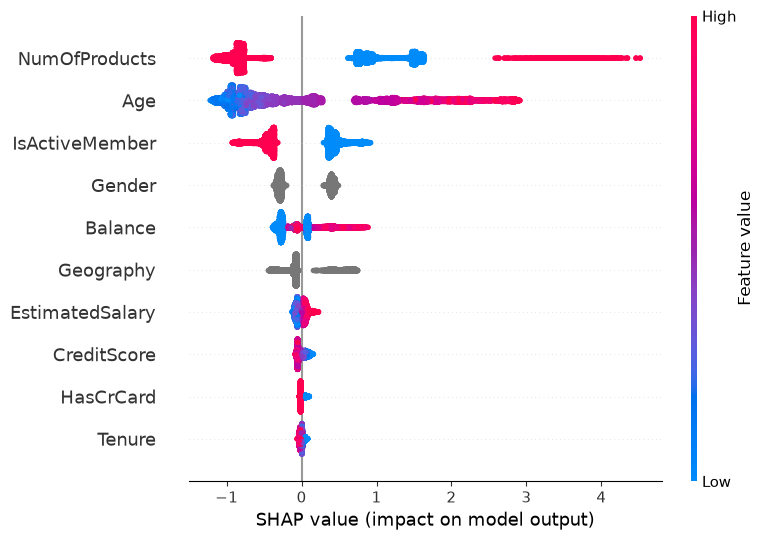

In [ ]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_raw)

shap.summary_plot(shap_values, X_raw)

Ранжирование по среднему |SHAP|:

```
   NumOfProducts  1.0194
             Age  0.9300
  IsActiveMember  0.4676
          Gender  0.3444
         Balance  0.2522
       Geography  0.2120
 EstimatedSalary  0.0559
     CreditScore  0.0519
       HasCrCard  0.0245
          Tenure  0.0178
```

Порядок почти совпадает с `feature_importance`, но не идеально:
`IsActiveMember` и `Gender` поднялись выше `Balance` в SHAP-ранжировании.
Разные методы (`PredictionValuesChange` vs SHAP) по-разному распределяют вклад
между коррелирующими признаками — это не противоречие, а нормальная особенность
интерпретации моделей: нет единственно верного способа поделить "общую" причину
между несколькими взаимосвязанными признаками.

## Шаг 3. Разбор одного клиента с высоким риском

In [ ]:
proba = final_model.predict_proba(X_raw)[:, 1]
top_client_idx = int(np.argmax(proba))
print(f"Client idx={top_client_idx}, predicted churn probability={proba[top_client_idx]:.4f}")
X_raw.iloc[top_client_idx]

Client idx=100, predicted churn probability=0.9872
CreditScore: 590.0
Geography: Germany
Gender: Female
Age: 47.0
Tenure: 5.0
Balance: 107233.85
NumOfProducts: 3
HasCrCard: 1
IsActiveMember: 0
EstimatedSalary: 131736.52


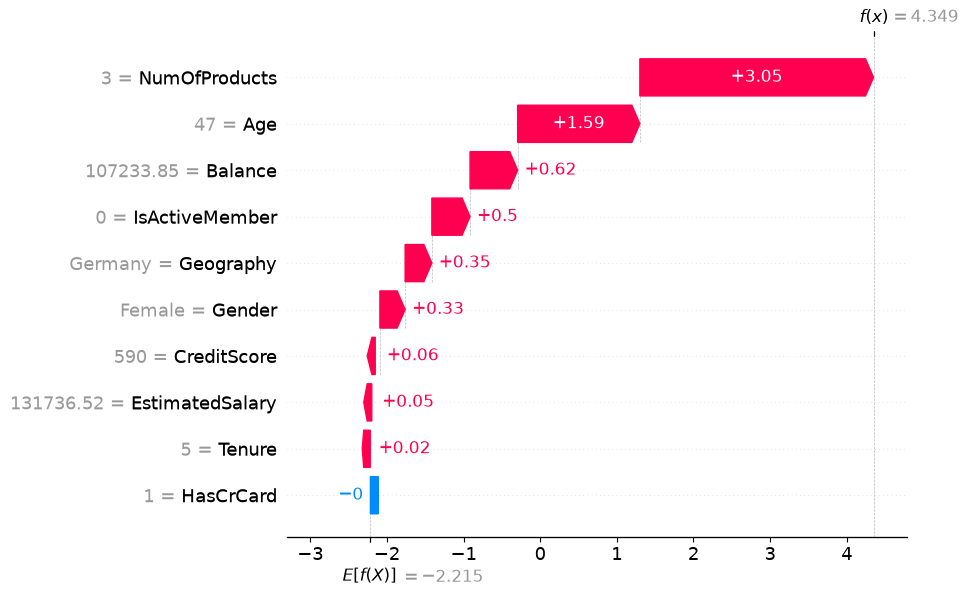

In [ ]:
expl = shap.Explanation(
    values=shap_values[top_client_idx],
    base_values=explainer.expected_value,
    data=X_raw.iloc[top_client_idx],
    feature_names=X_raw.columns.tolist(),
)
shap.waterfall_plot(expl)

**Портрет клиента с наивысшим предсказанным риском** (proba=0.9872):
`Geography=Germany`, `Gender=Female`, `Age=47.0`,
`NumOfProducts=3`, `IsActiveMember=0`.

Это практически идеальный "плохой" профиль по всем находкам EDA сразу: Германия
(самый высокий churn rate по стране), 3 продукта (churn rate 95.6% по туториалу 2),
неактивный клиент (`IsActiveMember=0`). Waterfall-график показывает, что именно
эти три признака (а не `CreditScore` или `EstimatedSalary`) толкнули предсказание
от базового уровня почти к 1.0 — ровно то, что можно было предсказать по EDA
ещё до всякого моделирования.

## Шаг 4. Сверка с EDA (туториал 2)

| Ожидание из EDA | Подтвердилось? |
|---|---|
| `NumOfProducts` — самый резкий сигнал (4.7% при 2 продуктах vs 95-100% при 3-4) | Да — #1 и в feature importance, и в SHAP |
| `Age` — самая сильная линейная корреляция (0.46) | Да — #2 в обоих рейтингах |
| `Geography` — Германия втрое выше churn rate | Частично — важен, но ниже `IsActiveMember`/`Balance`/`Gender` в обоих рейтингах: всего 3 категории дают меньше суммарной значимости, чем непрерывный `Age`, даже при сильном эффекте внутри категории |
| `IsActiveMember` — второй по силе категориальный сигнал | Да, и даже сильнее, чем ожидалось по разнице churn rate — в SHAP поднялся на 3-е место |
| `HasCrCard` — почти не влияет | Да — стабильно на последних местах в обоих рейтингах |

Главный вывод: EDA не была формальностью — все сильные сигналы, найденные
руками в туториале 2, подтвердились и моделью. Разошлось только относительное
место `Geography` — потому что важность модели учитывает не только "разницу
churn rate внутри категории", но и то, сколько вариации объясняет весь признак
целиком, а с 3 категориями это меньше, чем с непрерывным `Age`.

## Шаг 5. Итоговая таблица всего проекта

| Этап | Локальный ROC AUC | Kaggle private |
|---|---|---|
| Baseline: LogReg (туториал 3) | 0.8692 | 0.87486 |
| + Feature engineering (туториал 4) | 0.9246 | 0.92871 |
| CatBoost, 5-fold CV (туториал 5) | 0.9289 (OOF) | 0.93687 |
| + Тюнинг + блендинг CB/LGBM/LogReg (туториал 6) | 0.9291 (OOF) | **0.93703** |

**Итог: 0.93703 — примерно 3-е место** финального лидерборда (цель — топ-10,
порог 0.93344 — перекрыта с большим запасом).

Главные уроки пути:
- **Самый большой отдельный скачок** дало не тюнинг и не ансамбли, а понимание
  одного признака (`NumOfProducts`) через EDA.
- **Смена модели (логрегрессия → бустинг) дала больше**, чем весь ручной feature
  engineering вместе взятый — деревья сами нашли нелинейности, которые в
  туториале 4 искали руками.
- **Тюнинг и блендинг дали скромный, но положительный эффект** в самом конце —
  типичная картина, когда основная часть пути уже пройдена.
- **Интерпретируемость подтвердила EDA**, а не просто дала красивые графики —
  это и есть проверка, что весь пайплайн (от разведочного анализа до финальной
  модели) рассказывает одну и ту же, непротиворечивую историю про данные.